In [3]:
import numpy as np
from scipy.integrate import solve_ivp

# Parámetros de la tabla 2 
params = {
    # Crecimiento
    "mu_max"    : 1.09,    
    "K_glc"     : 1.0,    
    "K_gln"     : 0.3,     
    "kd_max"    : 0.69,   
    "kd_lac"    : 0.01,    
    "kd_amm"    : 0.06,    
    "kd_gln"    : 0.02,    
    "Yxv_glc"   : 1.09e8, 
    "Yxv_gln"   : 3.8e8,   
    "m_glc"     : 0.17 / 1e8, 
    "k_mglc"    : 19.0,    
    "Y_lac_glc" : 1.8,     
    "Y_amm_gln" : 0.85,    
    "alpha0"    : 2.57 / 1e8,  
    "beta"      : 0.35 / 1e8, 
    "K_mu"      : 0.02,    #
}


#CI


X0 = np.array([2.0e8,   # Xv  cells/L  (= 2e5 cells/mL × 1000 mL/L)
               25.0,    # Glc mM
               4.0,     # Gln mM
               0.0,     # Lac mM
               0.0,     # Amm mM
               0.0,     # MAb mg/L
               1.2])    # V   L

Glc_in = 25.0   # mM
Gln_in = 4.0    # mM
V_max  = 2.0    # L

# ------------------------------------------------------------------
# Tasas específicas (Tabla 1)
# Xv en cells/L → q's en mmol·L⁻¹·d⁻¹  o  mg·L⁻¹·d⁻¹
# ------------------------------------------------------------------
def kinetics(Xv, Glc, Gln, Lac, Amm, p):
    Glc = max(Glc, 0.0)
    Gln = max(Gln, 0.0)
    Lac = max(Lac, 0.0)
    Amm = max(Amm, 0.0)

    # Tasa de crecimiento (Monod doble sustrato)
    mu = (p["mu_max"]
          * Glc / (p["K_glc"] + Glc)
          * Gln / (p["K_gln"] + Gln))

    # Tasa de muerte (forma original del paper, con clamp de seguridad)
    denom_lac = max(p["mu_max"] - p["kd_lac"] * Lac, 0.05 * p["mu_max"])
    denom_amm = max(p["mu_max"] - p["kd_amm"] * Amm, 0.05 * p["mu_max"])
    kd = (p["kd_max"]
          / denom_lac
          / denom_amm
          * p["kd_gln"] / (p["kd_gln"] + Gln))

    # Consumo de glutamina [mmol·L⁻¹·d⁻¹]
    q_gln = mu * Xv / p["Yxv_gln"]

    # Consumo de glucosa [mmol·L⁻¹·d⁻¹]
    q_glc = (mu * Xv / p["Yxv_glc"]
             + p["m_glc"] * Xv * Glc / (p["k_mglc"] + Glc))

    # Subproductos [mmol·L⁻¹·d⁻¹]
    q_lac = p["Y_lac_glc"] * q_glc
    q_amm = p["Y_amm_gln"] * q_gln

    # MAb [mg·L⁻¹·d⁻¹]
    alpha_prime = p["alpha0"] / (p["K_mu"] + mu)
    q_MAb = (alpha_prime * mu + p["beta"]) * Xv

    return mu, kd, q_glc, q_gln, q_lac, q_amm, q_MAb


# ------------------------------------------------------------------
# ODEs fed-batch single feed (Ec. 1–7 del paper)
# Nota: ahora q_glc, q_gln, etc. ya incluyen Xv (son volumétricas)
# así que en las ODEs NO se multiplican por Xv de nuevo.
# ------------------------------------------------------------------
def fedbatch_ode(t, y, F_func, p, Glc_in, Gln_in, V_max):
    Xv, Glc, Gln, Lac, Amm, MAb, V = y

    Xv  = max(Xv,  0.0)
    Glc = max(Glc, 0.0)
    Gln = max(Gln, 0.0)
    Lac = max(Lac, 0.0)
    Amm = max(Amm, 0.0)
    MAb = max(MAb, 0.0)
    V   = max(V,   1e-6)

    F = F_func(t) if V < V_max else 0.0
    F = max(F, 0.0)
    D = F / V

    mu, kd, q_glc, q_gln, q_lac, q_amm, q_MAb = kinetics(Xv, Glc, Gln, Lac, Amm, p)

    dXv  = (mu - kd) * Xv  - D * Xv
    dGlc = (Glc_in - Glc) * D - q_glc
    dGln = (Gln_in - Gln) * D - q_gln
    dLac = q_lac - D * Lac
    dAmm = q_amm - D * Amm
    dMAb = q_MAb - D * MAb
    dV   = F

    return [dXv, dGlc, dGln, dLac, dAmm, dMAb, dV]


# ------------------------------------------------------------------
# Utilidad: simular con cualquier F_func(t)
# ------------------------------------------------------------------
def simulate(F_func, t_end=10.0, X0=X0, dt=0.01):
    t_eval = np.arange(0, t_end + dt, dt)
    sol = solve_ivp(
        fedbatch_ode, [0, t_end], X0,
        args=(F_func, params, Glc_in, Gln_in, V_max),
        t_eval=t_eval, method="LSODA", rtol=1e-6, atol=1e-9,
    )
    return {
        "t"         : sol.t,
        "Xv"        : sol.y[0],
        "Glc"       : sol.y[1],
        "Gln"       : sol.y[2],
        "Lac"       : sol.y[3],
        "Amm"       : sol.y[4],
        "MAb"       : sol.y[5],
        "V"         : sol.y[6],
        "MAb_total" : sol.y[5] * sol.y[6],
    }


# ------------------------------------------------------------------
# Verificación rápida
# ------------------------------------------------------------------
_ref = simulate(lambda t: 0.0, t_end=5.0)
print(f"✔  Celda 1 cargada.")
print(f"   Verificación batch (5 d):")
print(f"     MAb  = {_ref['MAb'][-1]:.1f} mg/L   (paper: ~67 mg/L)")
print(f"     Xv   = {_ref['Xv'][-1]/1e9:.2f} ×10⁹ cells/L")
print(f"     Glc  = {_ref['Glc'][-1]:.1f} mM     (debería haber bajado bastante)")
print(f"     Gln  = {_ref['Gln'][-1]:.2f} mM     (debería estar cerca de 0)")

✔  Celda 1 cargada.
   Verificación batch (5 d):
     MAb  = 68.5 mg/L   (paper: ~67 mg/L)
     Xv   = 0.16 ×10⁹ cells/L
     Glc  = 8.6 mM     (debería haber bajado bastante)
     Gln  = 0.00 mM     (debería estar cerca de 0)


Optimizando con differential_evolution (exploración global)...
  20 variables de control
  Puede tardar 3–5 minutos pero encontrará mejores soluciones

differential_evolution step 1: f(x)= -247.83828092932123
differential_evolution step 2: f(x)= -269.8853576485571
differential_evolution step 3: f(x)= -269.8853576485571
differential_evolution step 4: f(x)= -269.8853576485571
differential_evolution step 5: f(x)= -269.8853576485571
differential_evolution step 6: f(x)= -269.8853576485571
differential_evolution step 7: f(x)= -269.8853576485571
differential_evolution step 8: f(x)= -271.763740868852
differential_evolution step 9: f(x)= -271.763740868852
differential_evolution step 10: f(x)= -274.6294012250439
differential_evolution step 11: f(x)= -280.2895752215858
differential_evolution step 12: f(x)= -280.2895752215858
differential_evolution step 13: f(x)= -280.2895752215858
differential_evolution step 14: f(x)= -280.2895752215858
differential_evolution step 15: f(x)= -280.2895752215858
dif

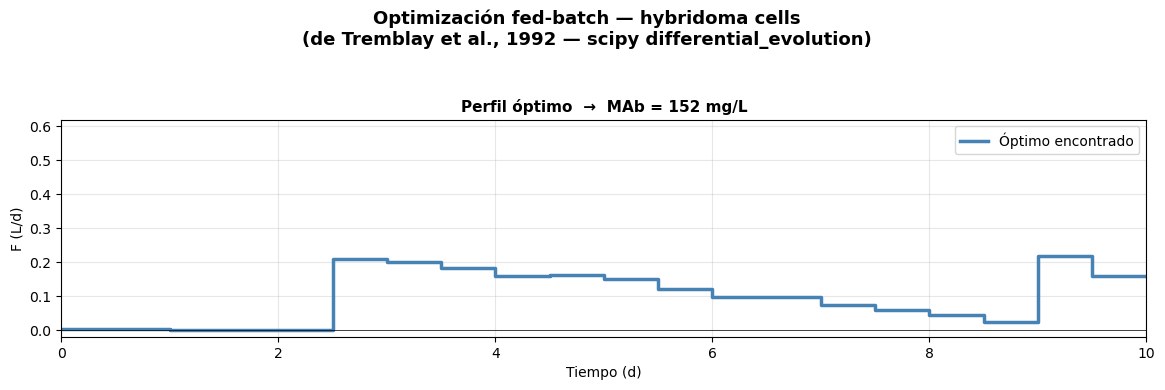

In [4]:
# ============================================================
# CELDA 2 — Optimización global con differential_evolution
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.integrate import solve_ivp
from scipy.optimize import differential_evolution

# ------------------------------------------------------------------
# Función objetivo
# ------------------------------------------------------------------
def objective(F_vec):
    """Simula con P flujos y devuelve -MAb·V."""
    y = X0.copy()
    P_local = len(F_vec)
    dt_step = 10.0 / P_local

    for k in range(P_local):
        t0 = k * dt_step
        t1 = t0 + dt_step
        F_k = float(F_vec[k])

        def ode(t, yy, F=F_k):
            return fedbatch_ode(t, yy, lambda tt: F,
                                params, Glc_in, Gln_in, V_max)

        try:
            sol = solve_ivp(ode, [t0, t1], y,
                            method="RK45", rtol=1e-5, atol=1e-8,
                            dense_output=False)
            if not sol.success:
                return 1e10
            y = sol.y[:, -1]
        except:
            return 1e10

    MAb_total = max(y[5], 0.0) * max(y[6], 0.0)
    return -MAb_total  # minimizar negativo = maximizar


# ------------------------------------------------------------------
# Optimización con differential_evolution
# ------------------------------------------------------------------
P = 20
F_min, F_max = 0.0, 0.50

print("Optimizando con differential_evolution (exploración global)...")
print(f"  {P} variables de control")
print(f"  Puede tardar 3–5 minutos pero encontrará mejores soluciones\n")

bounds = [(F_min, F_max)] * P

result = differential_evolution(
    objective,
    bounds,
    seed        = 42,
    maxiter     = 300,        # menos iteraciones que antes
    tol         = 1e-5,       # tolerancia relajada
    atol        = 1e-5,
    popsize     = 12,         # población más pequeña pero suficiente
    mutation    = (0.5, 1.5),
    recombination = 0.85,
    polish      = True,       # refinamiento final
    workers     = 1,
    disp        = True,
)

optimal_F = result.x
MAb_total_opt = -result.fun

print(f"\n✔ Optimización completada.")
print(f"  Iteraciones: {result.nit}")
print(f"  MAb·V óptimo = {MAb_total_opt:.1f} mg")


# ------------------------------------------------------------------
# Reconstruir trayectoria
# ------------------------------------------------------------------
def reconstruct(F_vec):
    y = X0.copy()
    P_local = len(F_vec)
    dt_step = 10.0 / P_local
    traj_t      = [0.0]
    traj_states = [y.copy()]

    for k in range(P_local):
        t0 = k * dt_step
        t1 = t0 + dt_step
        F_k = float(F_vec[k])

        def ode(t, yy, F=F_k):
            return fedbatch_ode(t, yy, lambda tt: F,
                                params, Glc_in, Gln_in, V_max)

        sol = solve_ivp(ode, [t0, t1], y,
                        method="RK45", rtol=1e-5, atol=1e-8,
                        t_eval=np.linspace(t0, t1, 15))
        y = sol.y[:, -1]
        for i in range(1, sol.y.shape[1]):
            traj_t.append(sol.t[i])
            traj_states.append(sol.y[:, i].copy())

    return np.array(traj_t), np.array(traj_states)

traj_t, traj_states = reconstruct(optimal_F)

final_MAb_conc  = traj_states[-1, 5]
final_MAb_total = traj_states[-1, 5] * traj_states[-1, 6]
final_V         = traj_states[-1, 6]

print(f"\n  MAb (concentración): {final_MAb_conc:.1f} mg/L")
print(f"  MAb (total):         {final_MAb_total:.1f} mg")
print(f"  Volumen final:       {final_V:.2f} L")
print(f"\n  Comparación con paper:")
print(f"    Paper esperado:    ~147 mg/L | ~294 mg total")
print(f"    Diagnóstico Fig1c: ~139 mg/L | ~277 mg total")
print(f"    Nuestro óptimo:    {final_MAb_conc:.0f} mg/L | {final_MAb_total:.0f} mg total")


# ------------------------------------------------------------------
# Referencias
# ------------------------------------------------------------------



fig = plt.figure(figsize=(14, 11))
fig.suptitle(
    "Optimización fed-batch — hybridoma cells\n"
    "(de Tremblay et al., 1992 — scipy differential_evolution)",
    fontsize=13, fontweight="bold"
)
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)

# (a) Perfil de alimentación
ax1 = fig.add_subplot(gs[0, :])
dt = 10.0 / len(optimal_F)
t_feed, F_feed = [], []
for i, F in enumerate(optimal_F):
    t_feed += [i * dt, (i + 1) * dt]
    F_feed += [F, F]
ax1.step(t_feed, F_feed, where="post", color="steelblue", lw=2.5, label="Óptimo encontrado")
ax1.set_xlabel("Tiempo (d)", fontsize=10)
ax1.set_ylabel("F (L/d)", fontsize=10)
ax1.set_title(f"Perfil óptimo  →  MAb = {final_MAb_conc:.0f} mg/L", fontsize=11, fontweight="bold")
ax1.set_xlim(0, 10)
ax1.set_ylim(-0.02, 0.62)
ax1.axhline(0, color="k", lw=0.5)
ax1.legend(loc="upper right")
ax1.grid(True, alpha=0.3)



plt.show()